# POKEMON

### Analitika kitabxanalarının yüklənməsi və Datasetin Gətirilməsi

In [1]:
import pandas as sema
import numpy as nuray
import matplotlib.pyplot as lamiye
import seaborn as orxan
orxan.set_theme(style="whitegrid")
df = sema.read_excel(r'C:\Users\ssm23\OneDrive\Desktop\Təkrar tapşırıqlar\Pokemon.xlsx')
print("Sütun adlarınız bunlardır:", df.columns.tolist())
df

Sütun adlarınız bunlardır: ['#', 'name', 'type1', 'type2', 'base_total', 'hp', 'attack', 'defense', 'sp_attack', 'sp_defense', 'speed', 'height_m', 'weight_kg', 'is_legendary', 'generation', 'capture_rate', 'base_happiness', 'percentage_male']


,#,name,type1,type2,base_total,hp,attack,defense,sp_attack,sp_defense,speed,height_m,weight_kg,is_legendary,generation,capture_rate,base_happiness,percentage_male
0,1,Bulbasaur,grass,poison,318,45,49,49,65,65,45,0.7,6.9,0,1,45,70,88.1
1,2,Ivysaur,grass,poison,405,60,62,63,80,80,60,1.0,13.0,0,1,45,70,88.1
2,3,Venusaur,grass,poison,625,80,100,123,122,120,80,2.0,100.0,0,1,45,70,88.1
3,4,Charmander,fire,NaN,309,39,52,43,60,50,65,0.6,8.5,0,1,45,70,88.1
4,5,Charmeleon,fire,NaN,405,58,64,58,80,65,80,1.1,19.0,0,1,45,70,88.1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
795,796,Celesteela,steel,flying,570,97,101,103,107,101,61,9.2,999.9,1,7,25,0,NaN
796,797,Kartana,grass,steel,570,59,181,131,59,31,109,0.3,0.1,1,7,255,0,NaN
797,798,Guzzlord,dark,dragon,570,223,101,53,97,53,43,5.5,888.0,1,7,15,0,NaN
798,799,Necrozma,psychic,NaN,600,97,107,101,127,89,79,2.4,230.0,1,7,3,0,NaN


#### Datasetdə ən çox yayılmış Pokemon növü hansıdır? Bu tip nə qədər Pokemon var?

In [5]:
butun_tipler = sema.concat([df['type1'], df['type2']]).value_counts()
tip_adi = butun_tipler.index[0]   
tip_sayi = butun_tipler.values[0] 
print(f"Ən çox yayılmış növ '{tip_adi}' növüdür və sayı {tip_sayi} dənədir.")

Ən çox yayılmış növ 'water' növüdür və sayı 131 dənədir.


#### Digər növləri ilə müqayisədə həddindən artıq yüksək və ya aşağı statistikaya malik hər hansı Pokemon varmı?

In [6]:
Q1 = df['base_total'].quantile(0.25)
Q3 = df['base_total'].quantile(0.75)
IQR = Q3 - Q1

yuxari_serhed = Q3 + (1.5 * IQR)
asagi_serhed = Q1 - (1.5 * IQR)

anormal_pokemonlar = df[(df['base_total'] > yuxari_serhed) | (df['base_total'] < asagi_serhed)]

print(f"base_total üzrə Yuxarı Sərhəd: {yuxari_serhed}")
print(f"base_total üzrə Aşağı Sərhəd: {asagi_serhed}\n")

if anormal_pokemonlar.empty:
    print("🔘v🔘 base_total göstəricisinə görə həddindən artıq yüksək və ya aşağı statistikaya malik hər hansı Pokemon yoxdur 🔘v🔘")
else:
    print("🔘v🔘 base_total göstəricisinə görə Outlier olan Pokemonlar 🔘v🔘")
    print(anormal_pokemonlar[['name', 'base_total']].sort_values(by='base_total', ascending=False))

base_total üzrə Yuxarı Sərhəd: 782.5
base_total üzrə Aşağı Sərhəd: 42.5

🔘v🔘 base_total göstəricisinə görə həddindən artıq yüksək və ya aşağı statistikaya malik hər hansı Pokemon yoxdur 🔘v🔘


#### Pokemonun capture rate ilə onun base total arasında əlaqə varmı? Bəs onun nadirliyi (legendary və ya deyil)?

In [7]:
df['capture_rate'] = sema.to_numeric(df['capture_rate'], errors='coerce')

korelyasiya = df['capture_rate'].corr(df['base_total'])

print(f" Capture Rate və Base Total arasındakı əlaqə - korrelyasiya: {korelyasiya:.2f}")
print("(Qeyd: Nəticə -1-ə nə qədər yaxındırsa, mənfi əlaqə bir o qədər güclüdür)\n")

muqayise = df.groupby('is_legendary')[['capture_rate', 'base_total']].mean()
muqayise.index = ['Adi Pokemon (0)', 'Əfsanəvi Pokemon (1)']
print(" /\\\\ /\\\\                                             /\\\\ /\\\\ ")
print(" ______                                              ______")
print("|🔘v🔘|| Nadirliyə (is_legendary) görə Ortalamalar |🔘v🔘||")
print(" ‾‾‾‾‾‾                                              ‾‾‾‾‾‾")
print(muqayise)

 Capture Rate və Base Total arasındakı əlaqə - korrelyasiya: -0.71
(Qeyd: Nəticə -1-ə nə qədər yaxındırsa, mənfi əlaqə bir o qədər güclüdür)

 /\\ /\\                                             /\\ /\\ 
 ______                                              ______
|🔘v🔘|| Nadirliyə (is_legendary) görə Ortalamalar |🔘v🔘||
 ‾‾‾‾‾‾                                              ‾‾‾‾‾‾
                      capture_rate  base_total
Adi Pokemon (0)         106.506849  410.358904
Əfsanəvi Pokemon (1)     17.985714  615.257143


#### Hansı Pokemon ən yüksək hücum statistikasına malikdir?

In [8]:
en_hucumcu = df.loc[df['attack'].idxmax()]
print(f"Ən yüksək Fiziki Hücum: {en_hucumcu['name']} ({en_hucumcu['attack']})")

en_sp_hucumcu = df.loc[df['sp_attack'].idxmax()]
print(f"Ən yüksək Xüsusi Hücum: {en_sp_hucumcu['name']} ({en_sp_hucumcu['sp_attack']})")

Ən yüksək Fiziki Hücum: Heracross (185)
Ən yüksək Xüsusi Hücum: Mewtwo (194)


#### Base total ilə HP, Attack, Defense, Special Attack, Special Defense və Speed kimi digər atributların hər biri arasında correlation nədir?

In [9]:
statistika = ['hp', 'attack', 'defense', 'sp_attack', 'sp_defense', 'speed']
korelyasiyalar = df[statistika].corrwith(df['base_total'])
print(" _________________________________________________________________")
print("|🔘v🔘 Base Total ilə digər statistikaların korrelyasiyası 🔘v🔘|")
print(" ‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾")
print(korelyasiyalar.sort_values(ascending=False))

 _________________________________________________________________
|🔘v🔘 Base Total ilə digər statistikaların korrelyasiyası 🔘v🔘|
 ‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾
sp_attack     0.740986
attack        0.729998
sp_defense    0.717958
defense       0.630151
hp            0.621062
speed         0.547575
dtype: float64


#### Əfsanəvi və əfsanəvi olmayan Pokemonun ortalama hücum  arasında əhəmiyyətli fərq varmı?

In [10]:
ortalamalar = (
    df.groupby('is_legendary')[['weight_kg', 'height_m']]
      .mean()
      .reset_index()
)
ortalamalar

,is_legendary,weight_kg,height_m
0,0,48.018425,1.056681
1,1,199.350725,2.281159


#### Hansı tip 1 və tip 2 kombinasiyaları Pokemonlar arasında ən çox yayılmışdır?

In [11]:
top_tipler = df[['type1', 'type2']].value_counts().reset_index(name='say')

print("🔘v🔘 Ən Çox Yayılmış Top 10 Tip Kombinasiyası 🔘v🔘\n")
print(top_tipler.head(10).to_string(index=False))

🔘v🔘 Ən Çox Yayılmış Top 10 Tip Kombinasiyası 🔘v🔘

 type1    type2  say
normal   flying   26
 grass   poison   14
   bug   flying   13
   bug   poison   11
 water   ground    9
 water   flying    7
  rock    water    6
 grass   flying    6
  rock   ground    6
  fire fighting    6


#### Pokemonun çəkisi və boyu arasında korrelyasiya varmı?

Sütun adlarınız bunlardır: ['#', 'name', 'type1', 'type2', 'base_total', 'hp', 'attack', 'defense', 'sp_attack', 'sp_defense', 'speed', 'height_m', 'weight_kg', 'is_legendary', 'generation', 'capture_rate', 'base_happiness', 'percentage_male']
Boy və Çəki arasındakı korrelyasiya: 0.63


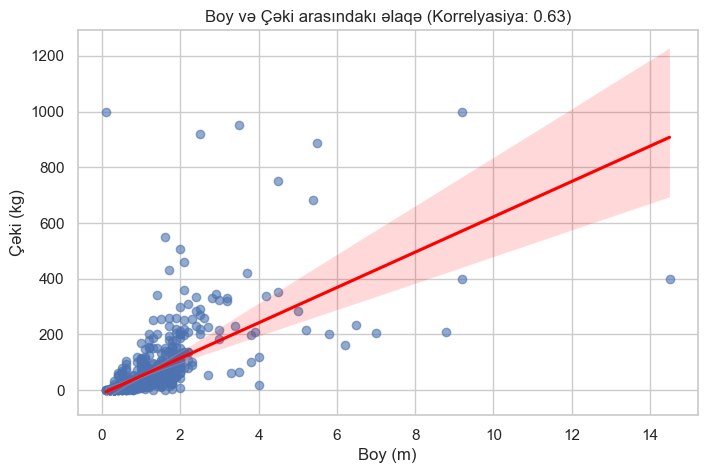

In [16]:
print("Sütun adlarınız bunlardır:", df.columns.tolist())

korelyasiya = df['height_m'].corr(df['weight_kg'])
print(f"Boy və Çəki arasındakı korrelyasiya: {korelyasiya:.2f}")

lamiye.figure(figsize=(8, 5))
orxan.regplot(data=df, x='height_m', y='weight_kg', scatter_kws={'alpha':0.6}, line_kws={'color':'red'})
lamiye.title(f'Boy və Çəki arasındakı əlaqə (Korrelyasiya: {korelyasiya:.2f})')
lamiye.xlabel('Boy (m)')
lamiye.ylabel('Çəki (kg)')
lamiye.show()

#### Hansı nəsil (generation) ən yüksək ortalama sürətə malikdir?

In [13]:
nesil_suret = df.groupby('generation')['speed'].mean().sort_values(ascending=False)

print("🔘v🔘 Nəsillərə Göre Ortalama Sürət (Speed) 🔘v🔘")
print(nesil_suret.round(2))

en_suretli = nesil_suret.idxmax()
print(f"\n Ən yüksək ortalama sürətə malik nəsil: Generation {en_suretli} ({nesil_suret.max():.2f} xal)")

🔘v🔘 Nəsillərə Göre Ortalama Sürət (Speed) 🔘v🔘
generation
1    70.15
4    70.07
6    66.65
5    66.52
3    63.58
7    63.33
2    61.61
Name: speed, dtype: float64

 Ən yüksək ortalama sürətə malik nəsil: Generation 1 (70.15 xal)


#### Base total paylanması əfsanəvi və əfsanəvi olmayan Pokemon arasında necə dəyişir?

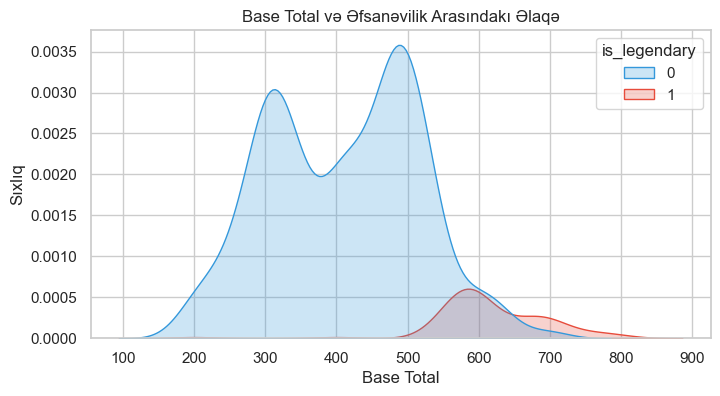

In [14]:
lamiye.figure(figsize=(8, 4))
orxan.kdeplot(data=df, x='base_total', hue='is_legendary', fill=True, palette=['#3498db', '#e74c3c'])

lamiye.title('Base Total və Əfsanəvilik Arasındakı Əlaqə')
lamiye.xlabel('Base Total')
lamiye.ylabel('Sıxlıq')

lamiye.show()

#### Müxtəlif Pokemon tipləri arasında Defense paylanmasında əhəmiyyətli fərq varmı?

C:\Users\ssm23\AppData\Local\Temp\ipykernel_12616\3774976532.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  orxan.boxplot(data=df, y='type1', x='defense', order=tiplerin_sirasi, palette='viridis')
C:\Users\ssm23\AppData\Local\Temp\ipykernel_12616\3774976532.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  orxan.boxplot(data=df, y='type2', x='defense', order=tiplerin_sirasi, palette='viridis')


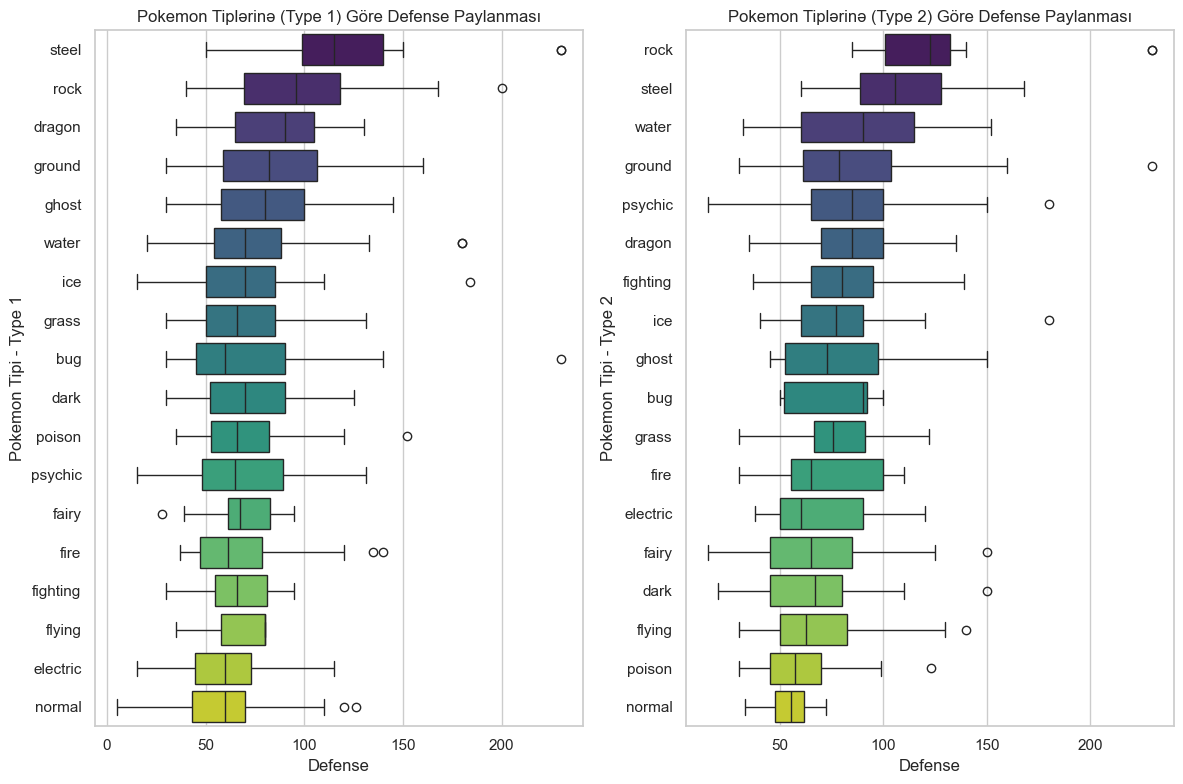

In [18]:
lamiye.figure(figsize=(12, 8))

tiplerin_sirasi = df.groupby('type1')['defense'].mean().sort_values(ascending=False).index

lamiye.subplot(1, 2, 1)
orxan.boxplot(data=df, y='type1', x='defense', order=tiplerin_sirasi, palette='viridis')
lamiye.title('Pokemon Tiplərinə (Type 1) Göre Defense Paylanması')
lamiye.xlabel('Defense')
lamiye.ylabel('Pokemon Tipi - Type 1')

tiplerin_sirasi = df.groupby('type2')['defense'].mean().sort_values(ascending=False).index

lamiye.subplot(1, 2, 2)
orxan.boxplot(data=df, y='type2', x='defense', order=tiplerin_sirasi, palette='viridis')
lamiye.title('Pokemon Tiplərinə (Type 2) Göre Defense Paylanması')
lamiye.xlabel('Defense')
lamiye.ylabel('Pokemon Tipi - Type 2')

lamiye.tight_layout()
lamiye.show()

#### Pokemonun adını input kimi qəbul edən və onun statistikalarının olduğu lüğətini qaytaran funksiya yazın.

In [114]:
def pokemon_statistikasi(ad):
    axtaris = df[df['name'].str.lower() == str(ad).strip().lower()].to_dict('records')
    
    if axtaris:
        return axtaris[0]
    return {"Xəta": f"'{ad}' adlı Pokemon tapılmadı."}
statistika = pokemon_statistikasi("Pikachu")
for acar, deyer in statistika.items():
    print(f"{acar}: {deyer}")


#: 25
name: Pikachu
type1: electric
type2: nan
base_total: 320
hp: 35
attack: 55
defense: 40
sp_attack: 50
sp_defense: 50
speed: 90
height_m: 0.4
weight_kg: 6.0
is_legendary: 0
generation: 1
capture_rate: 190
base_happiness: 70
percentage_male: 50.0


#### Percentage_male sütununda boş dəyərləri öz tipinin ortalaması ilə doldurun

In [118]:
df['percentage_male'] = df['percentage_male'].fillna(df.groupby('type1')['percentage_male'].transform('mean'))
df['percentage_male']

0      88.100000
1      88.100000
2      88.100000
3      88.100000
4      88.100000
         ...    
795    50.000000
796    58.978378
797    50.550000
798    51.058333
799    50.000000
Name: percentage_male, Length: 800, dtype: float64

#### Daha çox kişiyə yaxın olan pokemonlar daha güclüdür, yoxsa qadına yaxın olanlar?

In [121]:
kisi_yaxin_ort = df[df['percentage_male'] > 50]['base_total'].mean()
qadin_yaxin_ort = df[df['percentage_male'] < 50]['base_total'].mean()

print(f"Kişiyə yaxın olanların ortalama gücü : {kisi_yaxin_ort:.2f}")
print(f"Qadına yaxın olanların ortalama gücü: {qadin_yaxin_ort:.2f}")

if kisi_yaxin_ort > qadin_yaxin_ort:
    fərq = kisi_yaxin_ort - qadin_yaxin_ort
    print(f"NƏTİCƏ: Kişiyə yaxın olan Pokemonlar ortalama {fərq:.2f} fərq qədər daha güclüdür.")
elif qadin_yaxin_ort > kisi_yaxin_ort:
    fərq = qadin_yaxin_ort - kisi_yaxin_ort
    print(f"NƏTİCƏ: Qadına yaxın olan Pokemonlar ortalama {fərq:.2f} fərq qədər daha güclüdür.")
else:
    print("NƏTİCƏ: Hər iki qrupun ortalama gücü bərabərdir.")

Kişiyə yaxın olanların ortalama gücü : 437.92
Qadına yaxın olanların ortalama gücü: 404.92
NƏTİCƏ: Kişiyə yaxın olan Pokemonlar ortalama 32.99 fərq qədər daha güclüdür.


#### Əfsanəvi və ya əfsanəvi olmayan pokemonların ortalama çəkiləri və boyları arasında önəmli bir fərq var?

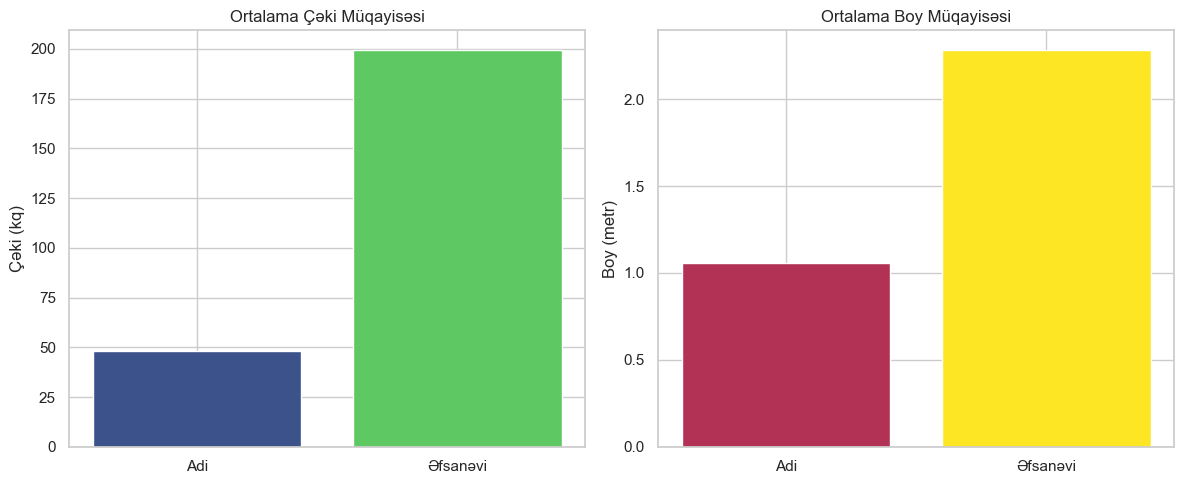

In [134]:
ortalamalar = df.groupby('is_legendary')[['weight_kg', 'height_m']].mean()

lamiye.figure(figsize=(12, 5))

lamiye.subplot(1, 2, 1)
lamiye.bar(['Adi', 'Əfsanəvi'], ortalamalar['weight_kg'], color=['#3b528b', '#5ec962'])
lamiye.title('Ortalama Çəki Müqayisəsi')
lamiye.ylabel('Çəki (kq)')

lamiye.subplot(1, 2, 2)
lamiye.bar(['Adi', 'Əfsanəvi'], ortalamalar['height_m'], color=['#b13254', '#fde725'])
lamiye.title('Ortalama Boy Müqayisəsi')
lamiye.ylabel('Boy (metr)')

lamiye.tight_layout()
lamiye.show()
from IPython.display import display, HTML

display(HTML("<h4 style='color: #ff4d4d; font-weight: bold;'>Vizualdan gördüyümüz üzərə deyə bilərik ki, əfsanəvi və ya əfsanəvi olmayan pokemonların ortalama çəkiləri və boyları arasında önəmli bir fərq var</h4>"))

#### Hansı tip1 və tip2 kombinasiyası daha xoşbəxtdir?

In [137]:
en_xosbext_tipler = df.groupby(['type1', 'type2'])['base_happiness'].mean().reset_index()
en_xosbext_tipler = en_xosbext_tipler.sort_values(by='base_happiness', ascending=False).round(2)
print("Ən xoşbəxt Type1 və Type2 kombinasiyaları:")
print(en_xosbext_tipler.head(10))

Ən xoşbəxt Type1 və Type2 kombinasiyaları:
       type1     type2  base_happiness
65     grass     grass          100.00
49      fire     steel          100.00
50      fire     water          100.00
110  psychic     grass          100.00
107  psychic      fire          100.00
26    dragon   psychic           90.00
99    poison  fighting           85.00
94    normal   psychic           80.00
75    ground    flying           76.67
84       ice    ground           70.00


#### Tiplər üzrə ortalama çəki və boyları tapın

In [142]:
t1 = df[['type1', 'weight_kg', 'height_m']].rename(columns={'type1': 'tip'})
t2 = df[['type2', 'weight_kg', 'height_m']].rename(columns={'type2': 'tip'})

birlesmis_df = sema.concat([t1, t2])
umumi_tipler_ort = birlasmis_df.groupby('tip')[['weight_kg', 'height_m']].mean().round(2).reset_index()
umumi_tipler_ort = umumi_tipler_ort.sort_values(by='weight_kg', ascending=False)

print(umumi_tipler_ort.to_string(index=False))

     tip  weight_kg  height_m
  dragon     156.67      2.11
   steel     147.14      1.51
  ground     126.18      1.58
     ice     113.26      1.39
    rock      97.12      1.27
fighting      71.31      1.30
    dark      68.34      1.29
   ghost      68.09      1.32
 psychic      65.34      1.08
    fire      63.38      1.16
   water      51.14      1.24
  flying      50.98      1.35
  normal      45.56      1.02
electric      41.37      0.99
   grass      33.69      0.96
     bug      33.26      0.89
  poison      29.78      1.07
   fairy      19.30      0.76


### Mən oynamaq üçün ən ideal pokemonu seçmək istəsəm, hansını seçməliyəm? Bunun üçün özünüzə uyğun xüsusi bir analiz aparın və seçdiyiniz pokemonu əsaslandırın

In [25]:
legends = df[df['is_legendary'] == 1].copy()
legends['max_attack_stat'] = legends[['attack', 'sp_attack']].max(axis=1)
legends['sweeper_score'] = legends['max_attack_stat'] + legends['speed']
top_candidates = legends.sort_values(
    by=['sweeper_score', 'base_total'],
    ascending=False
).head(1)

print("Təklif edilən İdeal Əfsanəvi Pokémonlar:")
display(top_candidates[['name', 'type1',
                        'max_attack_stat', 'speed',
                        'sweeper_score', 'base_total']])

ideal_pokemon = top_candidates.iloc[0]['name']

from IPython.display import display, HTML

display(HTML("""
<h3 style='color:blue; font-style:italic; font-weight:bold;'>
Nəticə: Tətbiq etdiyim sərt filtr şərtlərinə əsasən ən uyğun Pokémon kimi Mewtwo seçilmişdir. 
Onun yüksək sürəti, çox güclü xüsusi hücum qabiliyyəti və 780 ümumi güc göstəricisi Mewtwo-nu 
digər Pokémonlarla müqayisədə daha üstün və balanslı seçim edir.
</h3>
"""))

Təklif edilən İdeal Əfsanəvi Pokémonlar:


,name,type1,max_attack_stat,speed,sweeper_score,base_total
149,Mewtwo,psychic,194,140,334,780


#### Apardığınız analizlərin nəticəsinə uyğun olaraq vizuallaşdırmalar aparın və bir dashboard qurun

C:\Users\ssm23\AppData\Local\Temp\ipykernel_12616\4283638402.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  orxan.barplot(data=secilmis_df, x='name', y='sp_attack', palette=pokemon_rengleri)
C:\Users\ssm23\AppData\Local\Temp\ipykernel_12616\4283638402.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  orxan.barplot(data=secilmis_df, x='name', y='speed', palette=pokemon_rengleri)


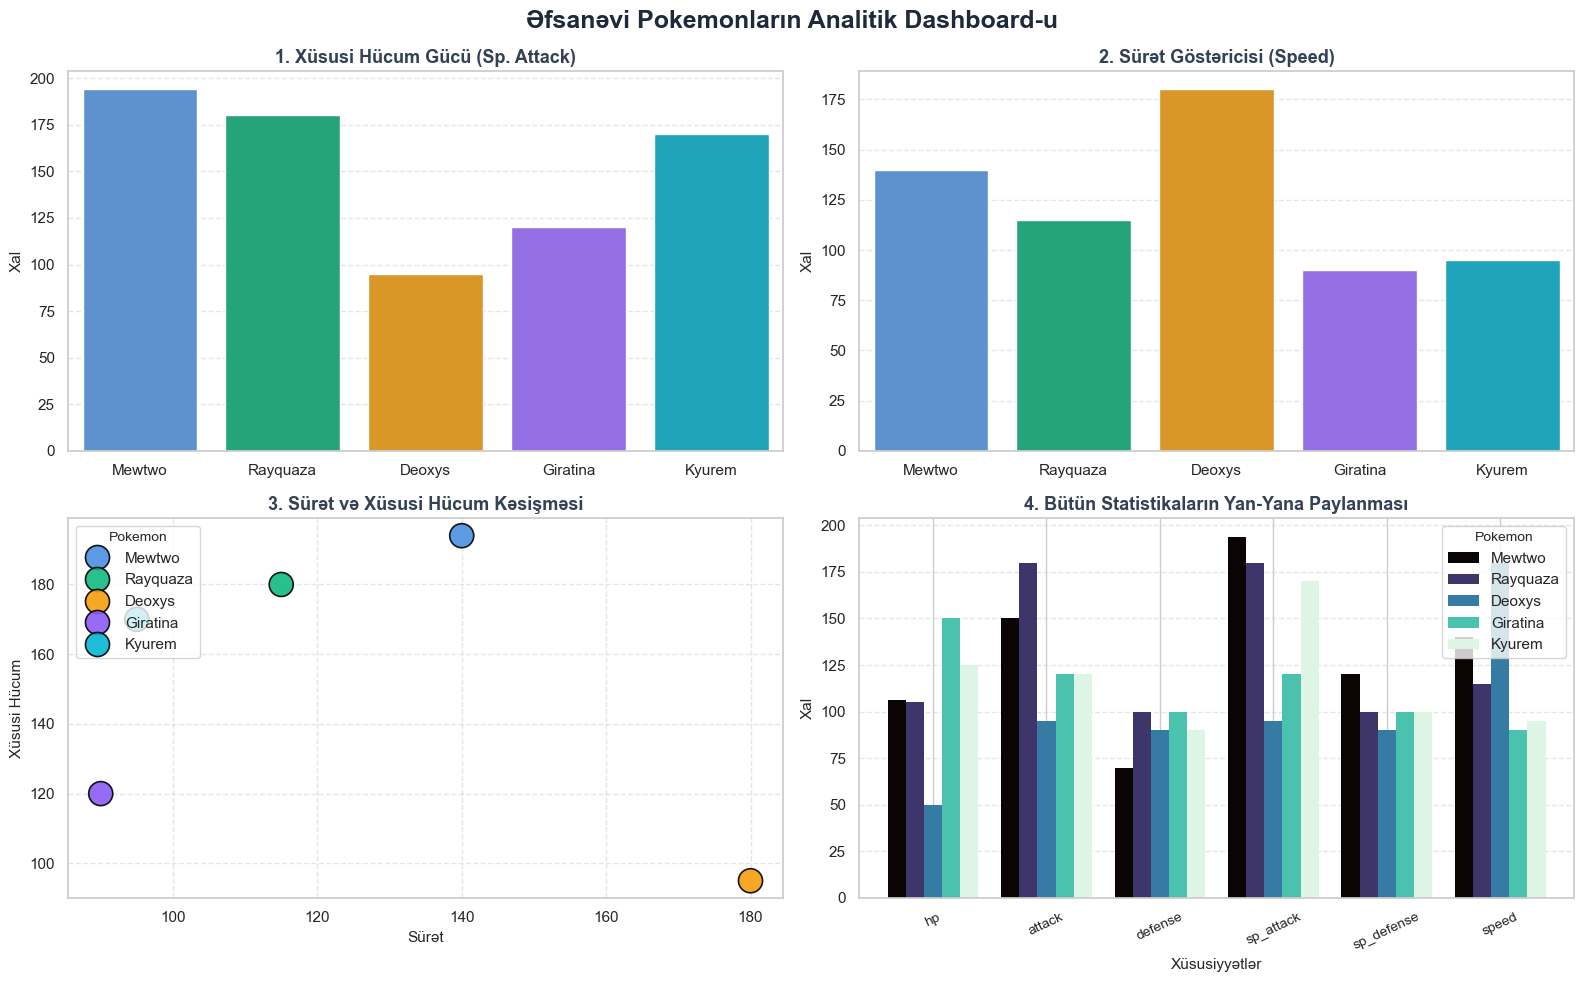

In [17]:
pokemonlar = ['Mewtwo', 'Giratina', 'Rayquaza', 'Kyurem', 'Deoxys']
secilmis_df = df[df['name'].isin(pokemonlar)].copy()

pokemon_rengleri = {
    'Mewtwo': '#4A90E2',    
    'Giratina': '#8B5CF6',  
    'Rayquaza': '#10B981',  
    'Kyurem': '#06B6D4',    
    'Deoxys': '#F59E0B'    
}

lamiye.figure(figsize=(16, 10))
lamiye.suptitle('Əfsanəvi Pokemonların Analitik Dashboard-u', fontsize=18, fontweight='bold', color='#1E293B', y=0.98)

lamiye.subplot(2, 2, 1)
orxan.barplot(data=secilmis_df, x='name', y='sp_attack', palette=pokemon_rengleri)
lamiye.title('1. Xüsusi Hücum Gücü (Sp. Attack)', fontsize=13, fontweight='bold', color='#334155')
lamiye.xlabel('')
lamiye.ylabel('Xal', fontsize=11)
lamiye.grid(axis='y', linestyle='--', alpha=0.5)

lamiye.subplot(2, 2, 2)
orxan.barplot(data=secilmis_df, x='name', y='speed', palette=pokemon_rengleri)
lamiye.title('2. Sürət Göstəricisi (Speed)', fontsize=13, fontweight='bold', color='#334155')
lamiye.xlabel('')
lamiye.ylabel('Xal', fontsize=11)
lamiye.grid(axis='y', linestyle='--', alpha=0.5)

lamiye.subplot(2, 2, 3)
orxan.scatterplot(
    data=secilmis_df, x='speed', y='sp_attack', hue='name', 
    s=300, palette=pokemon_rengleri, edgecolor='black', linewidth=1.2, alpha=0.9
)
lamiye.title('3. Sürət və Xüsusi Hücum Kəsişməsi', fontsize=13, fontweight='bold', color='#334155')
lamiye.xlabel('Sürət', fontsize=11)
lamiye.ylabel('Xüsusi Hücum', fontsize=11)
lamiye.legend(title='Pokemon', title_fontsize='10', loc='upper left')
lamiye.grid(True, linestyle='--', alpha=0.5)

lamiye.subplot(2, 2, 4)
cədvəl = secilmis_df[['name', 'hp', 'attack', 'defense', 'sp_attack', 'sp_defense', 'speed']].set_index('name')
cədvəl.T.plot(kind='bar', ax=lamiye.gca(), colormap='mako', edgecolor='none', width=0.8)
lamiye.title('4. Bütün Statistikaların Yan-Yana Paylanması', fontsize=13, fontweight='bold', color='#334155')
lamiye.xlabel('Xüsusiyyətlər', fontsize=11)
lamiye.ylabel('Xal', fontsize=11)
lamiye.legend(title='Pokemon', title_fontsize='10', loc='upper right', bbox_to_anchor=(1, 1))
lamiye.xticks(rotation=25, fontsize=10)
lamiye.grid(axis='y', linestyle='--', alpha=0.5)

lamiye.tight_layout()
lamiye.show()

In [33]:
print(r"""
            /\                 /\
           / \'._   (\_/)   _.'/ \
          /_.''._'--('.')--'_.''._\
          | \_ / `;=/ " \=;` \ _/ |
           \/ `\__|`\___/`|__/`  \/
                   \(/|\)/
""")


            /\                 /\
           / \'._   (\_/)   _.'/ \
          /_.''._'--('.')--'_.''._\
          | \_ / `;=/ " \=;` \ _/ |
           \/ `\__|`\___/`|__/`  \/
                   \(/|\)/

